# 03. Trazabilidad mes a mes de una obra (DuckDB)

Lee los CSV de `data/stg` (`sa_obras_publicas_infobras_<inicio>_<fin>.csv`; cada archivo contiene varios snapshots de cierre de mes identificados por `fecha_foto`) con **DuckDB**, los carga en una tabla **en memoria** y reconstruye la evolución de una obra (`codigo_infobras`) a lo largo de los snapshots.

**Contenido**
1. Parámetros
2. Carga en memoria (DuckDB)
3. Resumen de snapshots
4. Trazabilidad de la obra: variables clave por snapshot
5. Cambios detectados entre snapshots consecutivos
6. Evolución del avance físico y financiero (gráfico)

## 1. Parámetros

In [1]:
# ==============================================================================
# PARÁMETROS
# ==============================================================================
CODIGO_INFOBRAS = "540677"          # obra a analizar (texto)
PATRON_CSV = "sa_obras_publicas_infobras_*.csv"   # archivos de data/stg a cargar
# ==============================================================================

## 2. Carga en memoria con DuckDB

In [2]:
import time
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 60)


def obtener_raiz_proyecto() -> Path:
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents]:
        if (carpeta / "data" / "stg").exists():
            return carpeta
    return actual


PROJECT_ROOT = obtener_raiz_proyecto()
STG_DIR = PROJECT_ROOT / "data" / "stg"
archivos = sorted(STG_DIR.glob(PATRON_CSV))
assert archivos, f"No hay archivos {PATRON_CSV} en {STG_DIR}"

print(f"Archivos a cargar ({len(archivos)}):")
for a in archivos:
    print(f"  - {a.name}  ({a.stat().st_size / 1024**2:,.0f} MB)")

Archivos a cargar (6):
  - sa_obras_publicas_infobras_20250201_20250401.csv  (536 MB)
  - sa_obras_publicas_infobras_20250501_20250701.csv  (539 MB)
  - sa_obras_publicas_infobras_20250801_20251001.csv  (552 MB)
  - sa_obras_publicas_infobras_20251101_20260101.csv  (567 MB)
  - sa_obras_publicas_infobras_20260201_20260401.csv  (578 MB)
  - sa_obras_publicas_infobras_20260501_20260601.csv  (388 MB)


In [3]:
# Base de datos en memoria
con = duckdb.connect(database=":memory:")

# Columnas identificadoras: se fuerzan a texto para no perder ceros a la izquierda
COLS_TEXTO = {
    "codigo_infobras": "VARCHAR", "codigo_entidad": "VARCHAR", "codigo_infobras_obra_inicial": "VARCHAR",
    "codigo_unico": "VARCHAR", "codigo_snip": "VARCHAR", "ruc_1": "VARCHAR", "ruc_2": "VARCHAR",
}

ruta_glob = (STG_DIR / PATRON_CSV).as_posix()
t0 = time.time()
con.execute(f"""
    CREATE OR REPLACE TABLE obras AS
    SELECT * EXCLUDE (filename), regexp_extract(filename, '[^/\\\\]+$') AS archivo_stg
    FROM read_csv(?, union_by_name = true, filename = true, sample_size = -1, types = ?)
""", [ruta_glob, COLS_TEXTO])
print(f"Carga completada en {time.time() - t0:,.1f} s")

n_filas, n_cols = con.sql("SELECT count(*), (SELECT count(*) FROM information_schema.columns WHERE table_name = 'obras') FROM obras").fetchall()[0]
print(f"Tabla 'obras': {n_filas:,} filas x {n_cols} columnas")

Carga completada en 39.4 s
Tabla 'obras': 3,140,495 filas x 115 columnas


## 3. Resumen de snapshots cargados

In [4]:
con.sql("""
    SELECT fecha_foto,
           count(*)                       AS registros,
           count(DISTINCT codigo_infobras) AS obras_distintas,
           any_value(archivo_stg)          AS archivo
    FROM obras
    GROUP BY fecha_foto
    ORDER BY fecha_foto
""").df()

,fecha_foto,registros,obras_distintas,archivo
0,2025-02-01,179209,179201,sa_obras_publicas_infobras_20250201_20250401.csv
1,2025-03-01,179886,179877,sa_obras_publicas_infobras_20250201_20250401.csv
2,2025-04-01,181029,181019,sa_obras_publicas_infobras_20250201_20250401.csv
3,2025-05-01,178147,178137,sa_obras_publicas_infobras_20250501_20250701.csv
4,2025-06-01,178816,178806,sa_obras_publicas_infobras_20250501_20250701.csv
5,2025-07-01,179846,179846,sa_obras_publicas_infobras_20250501_20250701.csv
6,2025-08-01,181139,181139,sa_obras_publicas_infobras_20250801_20251001.csv
7,2025-09-01,182561,182561,sa_obras_publicas_infobras_20250801_20251001.csv
8,2025-10-01,184266,184266,sa_obras_publicas_infobras_20250801_20251001.csv
9,2025-11-01,186227,186227,sa_obras_publicas_infobras_20251101_20260101.csv


## 4. Trazabilidad de la obra

`trazabilidad_obra(codigo)` devuelve todas las filas de la obra ordenadas por `fecha_foto`. Se muestra transpuesta (variables en filas, snapshots en columnas) para comparar fácilmente la evolución mes a mes.

In [33]:
VARIABLES_CLAVE = [
    #"nombre_obra", 
    "estado_ejecucion",
    "fecha_inicio_obra",
    "estado_proyecto",
    #"ano_avance", 
    #"mes_avance", 
    "fecha_registro_avance", 
    "estado_actualizacion_registro_avance",
    "avance_fisico_programado_acumulado", 
    "avance_fisico_real_acumulado",
    "porcentaje_ejecucion_financiera",
    "monto_ejecucion_financiera_obra",
    "monto_valorizacion_programado_acum", 
    "monto_valorizacion_ejecutado_acum",
    "flg_existe_paralizacion", 
    "causal_paralizacion", 
    "fecha_paralizacion", 
    "numero_dias_paralizado",
    "fecha_fin_programada_obra", 
    "plazo_ejecucion_dias",
    "n_modificaciones", 
    "n_dias_modificaciones_plazo", 
    "nuevo_plazo_ejecucion_dias", 
    "fecha_finalizacion_reprogramada_obra",
    "n_adicionales_obra", 
    "monto_adicionales_obra_soles", 
    "n_deductivos_obra", 
    "monto_deductivo_obra_soles",
    "n_controversias", 
    "monto_contrato_soles_1", 
    "costo_obra_soles",
    "fecha_finalizacion_real", 
    "flg_tiene_recepcion_total", 
    "fecha_recepcion",
    "flg_tiene_liquidacion_obra", 
    "fecha_aprobacion_liquidacion_obra",
]


def trazabilidad_obra(codigo_infobras: str, columnas: list[str] | None = None) -> pd.DataFrame:
    """Filas de una obra en todos los snapshots, ordenadas por fecha_foto."""
    disponibles = {c for c in con.sql("SELECT * FROM obras LIMIT 0").columns}
    cols = [c for c in (columnas or VARIABLES_CLAVE) if c in disponibles]
    seleccion = ", ".join(["fecha_foto", *[f'"{c}"' for c in cols]])
    return con.execute(
        f"SELECT {seleccion} FROM obras WHERE codigo_infobras = ? ORDER BY fecha_foto", [str(codigo_infobras)]
    ).df()

CODIGO_INFOBRAS = '106748' #====================FILTRO===================#
df_obra = trazabilidad_obra(CODIGO_INFOBRAS)
print(f"Obra {CODIGO_INFOBRAS}: aparece en {len(df_obra)} snapshot(s)")

# Snapshots donde NO aparece la obra (entre los cargados)
todos = con.sql("SELECT DISTINCT fecha_foto FROM obras ORDER BY 1").df()["fecha_foto"]
ausentes = sorted(set(todos) - set(df_obra["fecha_foto"]))
if ausentes:
    print("No aparece en:", [pd.Timestamp(f).date().isoformat() for f in ausentes])

# Vista transpuesta: variables x snapshots
vista = df_obra.set_index(df_obra["fecha_foto"].dt.strftime("%Y-%m-%d")).drop(columns="fecha_foto").T
vista

Obra 106748: aparece en 17 snapshot(s)


fecha_foto,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01
estado_ejecucion,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución,En Ejecución
fecha_inicio_obra,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00,2021-02-06 00:00:00
estado_proyecto,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO,APROBADO
fecha_registro_avance,2024-12-02 00:00:00,2025-02-13 00:00:00,2025-03-24 00:00:00,2025-04-25 00:00:00,2025-05-26 00:00:00,2025-06-19 00:00:00,2025-07-09 00:00:00,2025-08-08 00:00:00,2025-09-09 00:00:00,2025-10-10 00:00:00,2025-11-10 00:00:00,2025-12-09 00:00:00,2026-01-19 00:00:00,2026-02-23 00:00:00,2026-03-25 00:00:00,2026-03-25 00:00:00,2026-03-25 00:00:00
estado_actualizacion_registro_avance,Actualizado,Actualizado,Actualizado,Actualizado,Actualizado,Actualizado,Actualizado,Actualizado,Actualizado,Avance Actualizado,Avance Actualizado,Avance Actualizado,Avance Actualizado,Avance Actualizado,Avance Actualizado,Avance Actualizado,Avance Actualizado
avance_fisico_programado_acumulado,100.0,100.0,100.0,100.0,95.09,100.0,100.0,94.54,91.45,95.51,97.39,100.0,100.0,100.0,100.0,100.0,100.0
avance_fisico_real_acumulado,48.86,48.86,48.86,48.86,51.5,53.91,56.26,59.43,60.98,61.86,63.73,64.12,64.12,64.12,64.12,64.12,64.12
porcentaje_ejecucion_financiera,75.98,76.54,74.22,74.22,75.83,78.04,80.35,82.24,82.21,89.51,91.05,91.05,94.75,95.09,95.16,95.16,95.16
monto_ejecucion_financiera_obra,81785639.51,84357542.5,84357542.5,84357542.5,84357542.5,87958378.23,90554775.13,92690744.24,98270638.8,99716328.37,101433446.2,101433446.2,105559378.7,105937256.4,107436723.7,107436723.7,107436723.7
monto_valorizacion_programado_acum,89833842.07,89883842.07,89883842.07,89883842.07,85952430.77,90426315.08,90426315.08,85102517.27,82327982.72,85981588.22,88189308.36,106855147.4,106855147.4,106855147.5,106855147.4,106855147.4,106855147.4


### Duplicados por snapshot

El grano esperado es 1 fila por obra y snapshot (ver regla `DQ003` del mapping). Se verifica si la obra tiene más de una fila en algún snapshot.

In [20]:
con.execute("""
    SELECT fecha_foto, count(*) AS filas
    FROM obras WHERE codigo_infobras = ?
    GROUP BY fecha_foto HAVING count(*) > 1 ORDER BY fecha_foto
""", [CODIGO_INFOBRAS]).df()

,fecha_foto,filas


## 5. Cambios entre snapshots consecutivos

Lista cada variable que cambió de valor respecto al snapshot anterior (valor anterior → valor nuevo).

In [21]:
def cambios_entre_snapshots(df: pd.DataFrame) -> pd.DataFrame:
    df = df.drop_duplicates("fecha_foto", keep="last").sort_values("fecha_foto").reset_index(drop=True)
    registros = []
    for i in range(1, len(df)):
        ant, act = df.iloc[i - 1], df.iloc[i]
        for col in df.columns.drop("fecha_foto"):
            a, b = ant[col], act[col]
            if (pd.isna(a) and pd.isna(b)) or (not pd.isna(a) and not pd.isna(b) and a == b):
                continue
            registros.append({
                "fecha_foto_anterior": ant["fecha_foto"].date(),
                "fecha_foto": act["fecha_foto"].date(),
                "variable": col,
                "valor_anterior": a,
                "valor_nuevo": b,
            })
    return pd.DataFrame(registros)


df_cambios = cambios_entre_snapshots(df_obra)
print(f"Cambios detectados: {len(df_cambios)}")
df_cambios

Cambios detectados: 18


,fecha_foto_anterior,fecha_foto,variable,valor_anterior,valor_nuevo
0,2025-03-01,2025-04-01,fecha_registro_avance,2025-01-21 00:00:00,2025-03-25 00:00:00
1,2025-03-01,2025-04-01,fecha_paralizacion,2025-01-01 00:00:00,2025-03-01 00:00:00
2,2025-05-01,2025-06-01,fecha_registro_avance,2025-03-25 00:00:00,2025-05-20 00:00:00
3,2025-05-01,2025-06-01,fecha_paralizacion,2025-03-01 00:00:00,2025-05-01 00:00:00
4,2025-07-01,2025-08-01,estado_ejecucion,Paralizada,En Ejecución
5,2025-07-01,2025-08-01,fecha_registro_avance,2025-05-20 00:00:00,2025-07-14 00:00:00
6,2025-07-01,2025-08-01,fecha_paralizacion,2025-05-01 00:00:00,2025-07-01 00:00:00
7,2025-09-01,2025-10-01,fecha_registro_avance,2025-07-14 00:00:00,2025-09-22 00:00:00
8,2025-09-01,2025-10-01,fecha_paralizacion,2025-07-01 00:00:00,2025-09-01 00:00:00
9,2025-10-01,2025-11-01,fecha_registro_avance,2025-09-22 00:00:00,2025-10-23 00:00:00


In [22]:
# Resumen: cuántas variables cambiaron en cada paso
if not df_cambios.empty:
    display(df_cambios.groupby(["fecha_foto_anterior", "fecha_foto"]).size().rename("variables_que_cambian").reset_index())

,fecha_foto_anterior,fecha_foto,variables_que_cambian
0,2025-03-01,2025-04-01,2
1,2025-05-01,2025-06-01,2
2,2025-07-01,2025-08-01,3
3,2025-09-01,2025-10-01,2
4,2025-10-01,2025-11-01,4
5,2025-12-01,2026-01-01,2
6,2026-03-01,2026-04-01,3


## 6. Evolución del avance físico y financiero

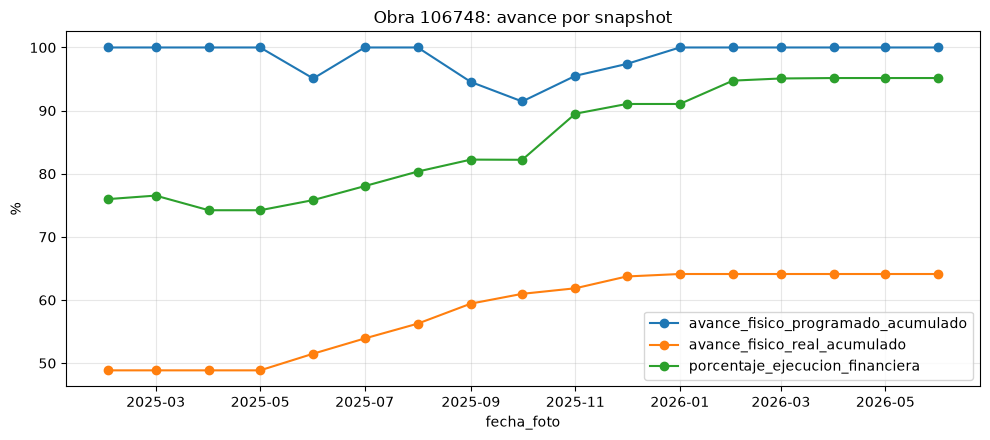

In [34]:
cols_plot = ["avance_fisico_programado_acumulado", "avance_fisico_real_acumulado", "porcentaje_ejecucion_financiera"]
cols_plot = [c for c in cols_plot if c in df_obra.columns and df_obra[c].notna().any()]

if cols_plot and len(df_obra) > 0:
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for c in cols_plot:
        ax.plot(df_obra["fecha_foto"], df_obra[c], marker="o", label=c)
    ax.set_title(f"Obra {CODIGO_INFOBRAS}: avance por snapshot")
    ax.set_ylabel("%")
    ax.set_xlabel("fecha_foto")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Sin datos de avance para graficar.")